<a href="https://colab.research.google.com/github/mariabalbo/CN/blob/main/Gauss_Seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Questão 5, 6 e 7**

<>:66: SyntaxWarning: invalid escape sequence '\|'
<>:66: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_621/3359571267.py:66: SyntaxWarning: invalid escape sequence '\|'
  ax2.semilogy(df_erro['k'], df_erro['erro'], 'ro-', label='$\|x^{(k)} - x^{(k-1)}\|_{\infty}$')


Número de iterações realizadas: 6
Solução aproximada obtida: x = 1.000000, y = 2.000000, z = -1.000000

Tabela de Iterações:
 k        x        y         z     erro
 0 0.000000 0.000000  0.000000      NaN
 1 0.600000 2.054545 -0.914545 2.054545
 2 0.988364 2.006711 -0.997002 0.388364
 3 1.000071 2.000279 -0.999986 0.011708
 4 1.000025 2.000004 -1.000005 0.000276
 5 1.000001 2.000000 -1.000000 0.000024
 6 1.000000 2.000000 -1.000000 0.000001


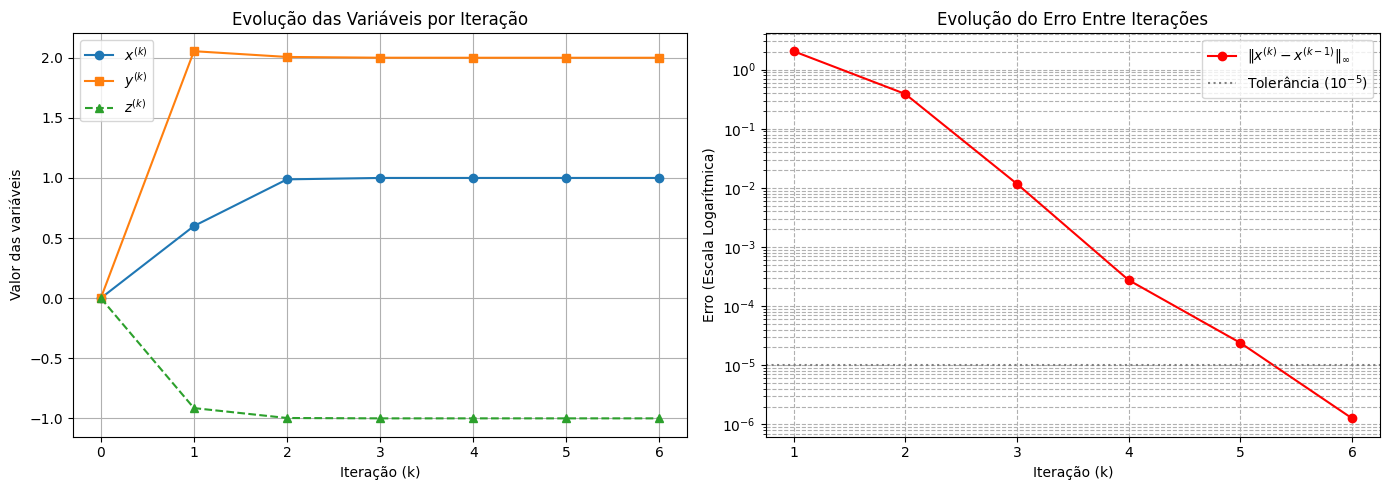

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def gauss_seidel(tol=1e-5, max_iter=100):
    x, y, z = 0.0, 0.0, 0.0

    historico = []
    historico.append({
        'k': 0,
        'x': x,
        'y': y,
        'z': z,
        'erro': None
    })

    for k in range(1, max_iter + 1):
        x_old, y_old, z_old = x, y, z

        x = (6.0 + y_old - 2.0 * z_old) / 10.0
        y = (22.0 + x + z_old) / 11.0
        z = (-10.0 - 2.0 * x + y) / 10.0

        erro = max(abs(x - x_old), abs(y - y_old), abs(z - z_old))

        historico.append({
            'k': k,
            'x': x,
            'y': y,
            'z': z,
            'erro': erro
        })

        if erro < tol:
            break

    return pd.DataFrame(historico)

# Executa o método
df = gauss_seidel()

# --- Questão 5: Resultado ---
solucao = df.iloc[-1]
print(f"Número de iterações realizadas: {int(solucao['k'])}")
print(f"Solução aproximada obtida: x = {solucao['x']:.6f}, y = {solucao['y']:.6f}, z = {solucao['z']:.6f}\n")

# --- Questão 6: Tabela organizada ---
print("Tabela de Iterações:")
print(df.to_string(index=False))

# --- Questão 7: Gráficos ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico (a): Convergência de x, y, z
ax1.plot(df['k'], df['x'], 'o-', label='$x^{(k)}$')
ax1.plot(df['k'], df['y'], 's-', label='$y^{(k)}$')
ax1.plot(df['k'], df['z'], '^--', label='$z^{(k)}$')
ax1.set_xlabel('Iteração (k)')
ax1.set_ylabel('Valor das variáveis')
ax1.set_title('Evolução das Variáveis por Iteração')
ax1.grid(True)
ax1.legend()

# Gráfico (b): Erro em escala logarítmica
df_erro = df.dropna(subset=['erro'])
ax2.semilogy(df_erro['k'], df_erro['erro'], 'ro-', label='$\|x^{(k)} - x^{(k-1)}\|_{\infty}$')
ax2.axhline(1e-5, color='gray', linestyle=':', label='Tolerância ($10^{-5}$)')
ax2.set_xlabel('Iteração (k)')
ax2.set_ylabel('Erro (Escala Logarítmica)')
ax2.set_title('Evolução do Erro Entre Iterações')
ax2.grid(True, which="both", ls="--")
ax2.legend()

plt.tight_layout()
plt.show()